In [21]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.preprocessing import PolynomialFeatures
import matplotlib.pyplot as plt


In [22]:
df=pd.read_csv('Ice_cream_selling_data_enriched2.csv')

In [23]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49 entries, 0 to 48
Data columns (total 5 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Temperature (°C)         49 non-null     float64
 1   Humidity (%)             49 non-null     float64
 2   Weekend                  49 non-null     int64  
 3   Advertising_Spend ($)    49 non-null     float64
 4   Ice Cream Sales (units)  49 non-null     float64
dtypes: float64(4), int64(1)
memory usage: 2.0 KB


In [24]:
df.head()

,Temperature (°C),Humidity (%),Weekend,Advertising_Spend ($),Ice Cream Sales (units)
0,-4.662263,85.6,0,504.92,41.842986
1,-4.316559,79.7,1,463.64,34.661120
2,-4.213985,85.7,0,193.03,39.383001
3,-3.949661,92.1,1,507.96,37.539845
4,-3.578554,77.1,1,341.13,32.284531


## 1. To check the data is linear or non linear?

In [25]:
df.corr()

,Temperature (°C),Humidity (%),Weekend,Advertising_Spend ($),Ice Cream Sales (units)
Temperature (°C),1.000000,-0.731627,-0.155631,-0.104670,-0.175184
Humidity (%),-0.731627,1.000000,0.179847,0.225624,0.291279
Weekend,-0.155631,0.179847,1.000000,0.052648,0.158949
Advertising_Spend ($),-0.104670,0.225624,0.052648,1.000000,0.365356
Ice Cream Sales (units),-0.175184,0.291279,0.158949,0.365356,1.000000


From analyzing correlation we can say that it a linear data.

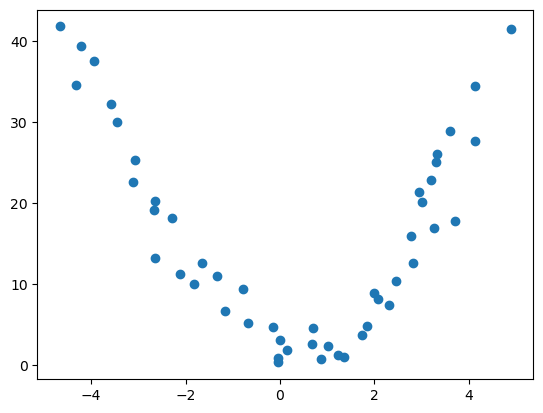

In [26]:
plt.scatter(df['Temperature (°C)'],df['Ice Cream Sales (units)'])

In [27]:
x= df.drop(columns=['Ice Cream Sales (units)'])
y= df['Ice Cream Sales (units)']

## 2. Model Creation

In [28]:
xtrain,xtest,ytrain,ytest=train_test_split(x,y,train_size=0.8,random_state=42)

## 3. Model Training

In [29]:
model= LinearRegression()
model.fit(xtrain,ytrain)

LinearRegression()

## 4. Error Analysis


In [30]:
# model evaluation
ytrain_pred=model.predict(xtrain)
train_score=r2_score(ytrain,ytrain_pred)
print('Train Score:',train_score)
# test score
ytest_pred=model.predict(xtest)
test_score=r2_score(ytest,ytest_pred)
print('Test Score:',test_score)

Train Score: 0.25625707388584895
Test Score: -0.6177687489100208


--> therfore, we can conclude that the model is underfit.



## using polynomial regression + linear regression 

--> Degree - 2

In [31]:
poly = PolynomialFeatures(degree=2)
updated_xtrain = poly.fit_transform(xtrain)

In [32]:
updated_xtest = poly.transform(xtest)

In [33]:
model_poly = LinearRegression()


model_poly.fit(updated_xtrain,ytrain)

LinearRegression()

In [34]:
# model evaluation
ytrain_pred=model_poly.predict(updated_xtrain)
train_score=r2_score(ytrain,ytrain_pred)
print('Train Score:',train_score)
# test score
ytest_pred=model_poly.predict(updated_xtest)
test_score=r2_score(ytest,ytest_pred)
print('Test Score:',test_score)

Train Score: 0.9488174152076437
Test Score: 0.8409577046350598


## Conclusion :-

--> therefore as now train score and test score is high, the model is now bestfit.

--> Degree - 3

In [35]:
poly1 = PolynomialFeatures(degree=3)
updated_xtrain= poly1.fit_transform(xtrain)
updated_xtest = poly1.transform(xtest)

In [36]:
model_poly1 = LinearRegression()


model_poly1.fit(updated_xtrain,ytrain)

LinearRegression()

In [37]:
# model evaluation
ytrain_pred=model_poly1.predict(updated_xtrain)
train_score1=r2_score(ytrain,ytrain_pred)
print('Train Score:',train_score1)
# test score
ytest_pred=model_poly1.predict(updated_xtest)
test_score1=r2_score(ytest,ytest_pred)
print('Test Score:',test_score1)

Train Score: 0.7280781207103215
Test Score: -2.5142712598637167


## Conclusion :-
--> therefore the model is now overfit

--> Degree - 4

In [38]:
poly2 = PolynomialFeatures(degree=4)
updated_xtrain= poly2.fit_transform(xtrain)
updated_xtest = poly2.transform(xtest)

In [39]:
model_poly2 = LinearRegression()


model_poly2.fit(updated_xtrain,ytrain)

LinearRegression()

In [40]:
# model evaluation
ytrain_pred=model_poly2.predict(updated_xtrain)
train_score1=r2_score(ytrain,ytrain_pred)
print('Train Score:',train_score1)
# test score
ytest_pred=model_poly2.predict(updated_xtest)
test_score1=r2_score(ytest,ytest_pred)
print('Test Score:',test_score1)

Train Score: 1.0
Test Score: 0.05302010178036909


## Conclusion :-

--> therefore as now train score is high but test score is low, the model is now Overfit